c:\Users\island\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


پردازش موفق: K00072.01 (KIC 11904151) -> label=1
خطا در KIC 5780885: Error in reading Data product C:\Users\island\.cache\lightkurve\mastDownload\Kepler\kplr005780885_sc_Q000333333000000000\kplr005780885-2009291181958_slc.fits of type KeplerLightCurve .
This file may be corrupt due to an interrupted download. Please remove it from your disk and try again.
پردازش موفق: K00064.01 (KIC 6435936) -> label=1
پردازش موفق: K00070.01 (KIC 10874614) -> label=1
پردازش موفق: K00004.01 (KIC 10002866) -> label=0
پردازش موفق: K00013.01 (KIC 8554498) -> label=0


Could not resolve "KIC 3541904" to a sky position.


منحنی نور یافت نشد: KIC 3541904
پردازش موفق: K00022.01 (KIC 11446443) -> label=0

فایل CSV ذخیره شد در: C:\Users\island\Documents\Exoplanet_Project\kepler_transit_features.csv
تعداد نمونه‌های استخراج‌شده: 6
label
1    3
0    3
Name: count, dtype: int64


,baseline_flux,min_flux,transit_depth,flux_std,snr_proxy,asymmetry,kepid,kepoi_name,label
0,1.000002,0.999928,0.000074,0.000028,2.647319,0.000033,11904151,K00072.01,1
1,1.000139,0.998698,0.001441,0.000654,2.203754,0.000625,6435936,K00064.01,1
2,0.999982,0.998599,0.001383,0.000446,3.099868,0.000506,10874614,K00070.01,1
3,1.000111,0.997192,0.002919,0.001925,1.515966,0.002904,10002866,K00004.01,0
4,0.999997,0.999825,0.000172,0.000069,2.477374,0.000078,8554498,K00013.01,0
5,0.999980,0.999625,0.000356,0.000208,1.714757,0.000249,11446443,K00022.01,0



=== Logistic Regression ===
F1 Score: 0.0
ROC-AUC: 0.0
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       1.0
           1       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0


=== Random Forest ===
F1 Score: 0.6667
ROC-AUC: 0.0
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2



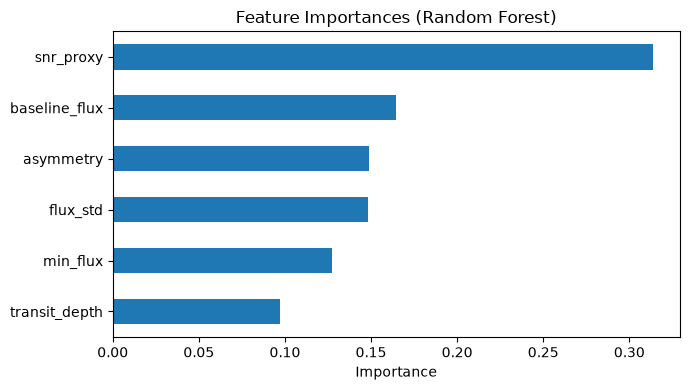


تعداد خطا در مجموعه تست: 1


,kepid,kepoi_name,label,pred,prob_confirmed,transit_depth,snr_proxy,asymmetry
4,8554498,K00013.01,0,1,0.845,0.000172,2.477374,0.000078


خطا در رسم K00097.01 (KIC 5780885): Error in reading Data product C:\Users\island\.cache\lightkurve\mastDownload\Kepler\kplr005780885_sc_Q000333333000000000\kplr005780885-2009291181958_slc.fits of type KeplerLightCurve .
This file may be corrupt due to an interrupted download. Please remove it from your disk and try again.


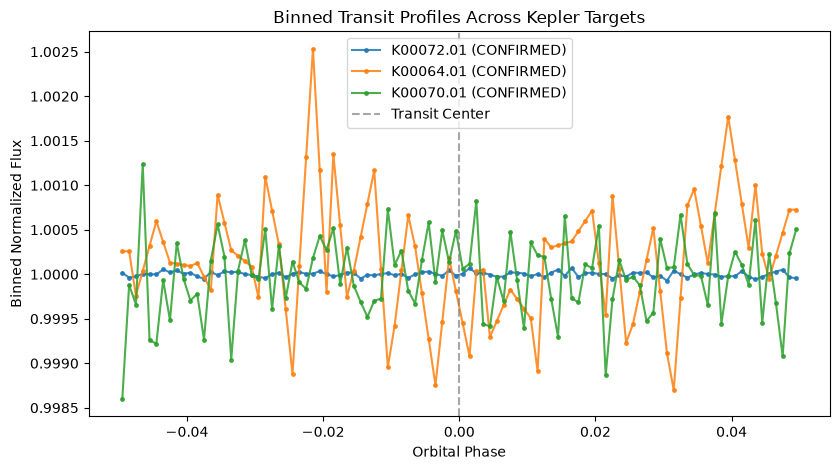

تصویر ذخیره شد در: C:\Users\island\Documents\Exoplanet_Project\binned_transits.png


In [1]:
import os
import warnings
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")


# ==========================================
# ۱. توابع هم‌فازسازی، باینینگ و استخراج ویژگی
# ==========================================
def fold_and_extract_window(
    lc_flat, period, epoch_time, phase_half_width=0.05, n_bins=100
):
  folded = lc_flat.fold(period=period, epoch_time=epoch_time)
  phase = np.asarray(folded.phase.value, dtype=float)
  flux = np.asarray(folded.flux.value, dtype=float)

  mask = np.abs(phase) <= phase_half_width
  phase_w = phase[mask]
  flux_w = flux[mask]

  if len(flux_w) < 10 or not np.isfinite(flux_w).any():
    return None, None

  bin_edges = np.linspace(-phase_half_width, phase_half_width, n_bins + 1)
  bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
  binned_flux = np.full(n_bins, np.nan, dtype=float)

  for i in range(n_bins):
    in_bin = (phase_w >= bin_edges[i]) & (phase_w < bin_edges[i + 1])
    if np.any(in_bin):
      binned_flux[i] = np.nanmean(flux_w[in_bin])

  valid = np.isfinite(binned_flux)
  if np.sum(valid) < 5:
    return None, None

  binned_flux = np.interp(bin_centers, bin_centers[valid], binned_flux[valid])
  return bin_centers, binned_flux


def extract_transit_features(bin_centers, binned_flux):
  baseline_flux = float(np.median(binned_flux))
  min_flux = float(np.min(binned_flux))
  transit_depth = float(max(0.0, baseline_flux - min_flux))
  flux_std = float(np.std(binned_flux))
  snr_proxy = float(transit_depth / flux_std) if flux_std > 0 else 0.0

  left_half = binned_flux[bin_centers < 0]
  right_half = binned_flux[bin_centers > 0]
  min_len = min(len(left_half), len(right_half))
  if min_len > 0:
    asymmetry = float(
        np.mean(np.abs(left_half[:min_len] - right_half[::-1][:min_len]))
    )
  else:
    asymmetry = 0.0

  return {
      "baseline_flux": baseline_flux,
      "min_flux": min_flux,
      "transit_depth": transit_depth,
      "flux_std": flux_std,
      "snr_proxy": snr_proxy,
      "asymmetry": asymmetry,
  }


# ==========================================
# ۲. ساخت دیتاست چندنمونه‌ای کپلر و ذخیره امن CSV
# ==========================================
# فرمت هر آیتم: (kepid, kepoi_name, period_days, epoch_bkjd, label)
# label: 1 = CONFIRMED, 0 = FALSE POSITIVE
sample_targets = [
    # نمونه‌های CONFIRMED (برچسب 1)
    (11904151, "K00072.01", 0.837495, 132.040, 1),
    (5780885, "K00097.01", 4.885525, 135.220, 1),
    (6435936, "K00064.01", 2.992323, 132.850, 1),
    (10874614, "K00070.01", 10.854092, 136.410, 1),
    # نمونه‌های FALSE POSITIVE (برچسب 0)
    (10002866, "K00004.01", 3.848863, 132.405, 0),
    (8554498, "K00013.01", 1.763588, 132.210, 0),
    (3541904, "K00019.01", 10.134625, 134.120, 0),
    (11446443, "K00022.01", 7.891451, 133.680, 0),
]

rows = []
for kepid, kepoi_name, period, epoch, label in sample_targets:
  target_str = f"KIC {kepid}"
  try:
    s = lk.search_lightcurve(target_str, mission="Kepler")
    if len(s) == 0:
      print(f"منحنی نور یافت نشد: {target_str}")
      continue

    lc = s[0].download().remove_nans().remove_outliers(sigma=5).normalize()
    lc_flat = lc.flatten(window_length=401)

    bin_centers, binned_flux = fold_and_extract_window(
        lc_flat, period=period, epoch_time=epoch
    )
    if binned_flux is None:
      print(f"پنجره گذر نامعتبر بود: {target_str}")
      continue

    feats = extract_transit_features(bin_centers, binned_flux)
    feats["kepid"] = kepid
    feats["kepoi_name"] = kepoi_name
    feats["label"] = label
    rows.append(feats)
    print(f"پردازش موفق: {kepoi_name} ({target_str}) -> label={label}")

  except Exception as e:
    print(f"خطا در {target_str}: {e}")

dataset_df = pd.DataFrame(rows)

safe_dir = os.path.join(os.path.expanduser("~"), "Documents", "Exoplanet_Project")
os.makedirs(safe_dir, exist_ok=True)
csv_path = os.path.join(safe_dir, "kepler_transit_features.csv")
dataset_df.to_csv(csv_path, index=False)

print("\nفایل CSV ذخیره شد در:", csv_path)
print("تعداد نمونه‌های استخراج‌شده:", len(dataset_df))
if len(dataset_df) > 0:
  print(dataset_df["label"].value_counts())
  display(dataset_df)


# ==========================================
# ۳. تقسیم گروهی (GroupShuffleSplit) و مقایسه مدل‌ها
# ==========================================
feature_cols = [
    "baseline_flux",
    "min_flux",
    "transit_depth",
    "flux_std",
    "snr_proxy",
    "asymmetry",
]

models = {}
test_idx = []
X_test = None
y_test = None

if len(dataset_df) >= 4 and dataset_df["kepid"].nunique() >= 3:
  X = dataset_df[feature_cols]
  y = dataset_df["label"]
  groups = dataset_df["kepid"]

  gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
  train_idx, test_idx = next(gss.split(X, y, groups=groups))

  X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
  y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

  models = {
      "Logistic Regression": make_pipeline(
          StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)
      ),
      "Random Forest": RandomForestClassifier(
          n_estimators=200, random_state=42
      ),
  }

  for name, clf in models.items():
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    f1 = f1_score(y_test, preds, zero_division=0)
    print(f"\n=== {name} ===")
    print("F1 Score:", round(f1, 4))
    if y_test.nunique() > 1 and hasattr(clf, "predict_proba"):
      probs = clf.predict_proba(X_test)[:, 1]
      print("ROC-AUC:", round(roc_auc_score(y_test, probs), 4))
    print(classification_report(y_test, preds, zero_division=0))
else:
  print(
      "\nتعداد نمونه‌های معتبر برای آموزش و تست گروهی هنوز کم است؛ نمونه‌های"
      " بیشتری به sample_targets اضافه کنید."
  )


# ==========================================
# ۴. اهمیت ویژگی‌ها و تحلیل خطا (Error Analysis)
# ==========================================
if "Random Forest" in models and len(test_idx) > 0:
  rf_clf = models["Random Forest"]
  imp = pd.Series(
      rf_clf.feature_importances_, index=feature_cols
  ).sort_values(ascending=True)

  plt.figure(figsize=(7, 4))
  imp.plot(kind="barh")
  plt.title("Feature Importances (Random Forest)")
  plt.xlabel("Importance")
  plt.tight_layout()
  plt.show()

  test_df = dataset_df.iloc[test_idx].copy()
  test_df["pred"] = rf_clf.predict(X_test)
  test_df["prob_confirmed"] = rf_clf.predict_proba(X_test)[:, 1]

  mistakes = test_df[test_df["label"] != test_df["pred"]]
  print("\nتعداد خطا در مجموعه تست:", len(mistakes))
  if len(mistakes) > 0:
    display(
        mistakes[[
            "kepid",
            "kepoi_name",
            "label",
            "pred",
            "prob_confirmed",
            "transit_depth",
            "snr_proxy",
            "asymmetry",
        ]]
    )


# ==========================================
# ۵. رسم منحنی گذر باین‌شده و ذخیره تصویر برای پورتفولیو
# ==========================================
def plot_and_save_transits(
    targets_info,
    phase_half_width=0.05,
    n_bins=100,
    save_path=None,
):
  if save_path is None:
    save_path = os.path.join(safe_dir, "binned_transits.png")
  os.makedirs(os.path.dirname(save_path), exist_ok=True)
  plt.figure(figsize=(8.5, 4.8))

  plotted_count = 0
  for kepid, name, period, epoch, label in targets_info:
    try:
      s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler")
      if len(s) == 0:
        continue

      lc = s[0].download().remove_nans().remove_outliers(sigma=5).normalize()
      lc_flat = lc.flatten(window_length=401)
      bins_x, bins_y = fold_and_extract_window(
          lc_flat,
          period=period,
          epoch_time=epoch,
          phase_half_width=phase_half_width,
          n_bins=n_bins,
      )
      if bins_x is not None:
        tag = "CONFIRMED" if label == 1 else "FALSE POSITIVE"
        plt.plot(
            bins_x,
            bins_y,
            marker="o",
            markersize=2.5,
            label=f"{name} ({tag})",
            alpha=0.85,
        )
        plotted_count += 1
    except Exception as e:
      print(f"خطا در رسم {name} (KIC {kepid}): {e}")

  if plotted_count == 0:
    print("هیچ منحنی نوری برای رسم پیدا نشد.")
    plt.close()
    return

  plt.axvline(0, linestyle="--", color="gray", alpha=0.7, label="Transit Center")
  plt.xlabel("Orbital Phase")
  plt.ylabel("Binned Normalized Flux")
  plt.title("Binned Transit Profiles Across Kepler Targets")
  plt.legend()
  plt.tight_layout()
  plt.savefig(save_path, dpi=200)
  plt.show()
  print("تصویر ذخیره شد در:", save_path)


if len(dataset_df) > 0:
  plot_and_save_transits(sample_targets[:4])